# 7. Using the models proactively

* **Recommend** a standard grade and a cooling route for a property specification, using the *lower*
  90 % bound so the recommendation is robust.
* **Map the strength-ductility trade-off** that standard grades can deliver, furnace vs air cooling (only real
  grades are searched; no composition is invented).
* **Plan experiments**: show that adding the most uncertain grade first learns faster than random, that a
  few local measurements recalibrate the model to a new product, and produce a pre-registered prediction
  sheet for the laboratory.

In [1]:
import sys, warnings
from pathlib import Path
warnings.filterwarnings("ignore")
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))
import pandas as pd, numpy as np
from IPython.display import Image, display, Markdown
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 30)
pd.set_option("display.float_format", lambda v: f"{v:,.3g}")
R = ROOT / "results"; FIG = ROOT / "figures"
def fig(name, width=1000):
    display(Image(filename=str(FIG / f"{name}.png"), width=width))

In [2]:
r = pd.read_csv(R / "s07_recommendations.csv")
r[["spec", "grade", "option", "UTS_MPa_lo90", "YS_MPa_lo90", "El_pct_lo90", "CE_IIW"]]

,spec,grade,option,UTS_MPa_lo90,YS_MPa_lo90,El_pct_lo90,CE_IIW
0,"YS >= 300 MPa and El >= 28 %, best weldability",AISI 1020,"air cooled, 25 mm",403,300,33,0.324
1,"YS >= 300 MPa and El >= 28 %, best weldability",AISI 1023,"air cooled, 25 mm",413,307,32.4,0.344
2,"YS >= 300 MPa and El >= 28 %, best weldability",AISI 1025,"air cooled, 25 mm",425,313,31.4,0.369
3,"YS >= 300 MPa and El >= 28 %, best weldability",AISI 1021,"air cooled, 25 mm",433,303,31.8,0.374
4,"YS >= 300 MPa and El >= 28 %, best weldability",AISI 1022,"air cooled, 25 mm",443,303,31.4,0.39
5,"YS >= 300 MPa and El >= 28 %, best weldability",AISI 15B21H,"air cooled, 25 mm",449,300,30.9,0.407
6,"YS >= 300 MPa and El >= 28 %, best weldability",AISI 1026,"air cooled, 25 mm",458,312,30.4,0.419
7,"YS >= 300 MPa and El >= 28 %, best weldability",AISI 1029,"air cooled, 25 mm",474,315,29.5,0.449
8,UTS >= 750 MPa and El >= 18 % without quench-a...,AISI 1340H,"air cooled, 25 mm",777,507,18.5,0.74
9,UTS >= 750 MPa and El >= 18 % without quench-a...,AISI 5145H,"air cooled, 25 mm",762,439,19,0.772


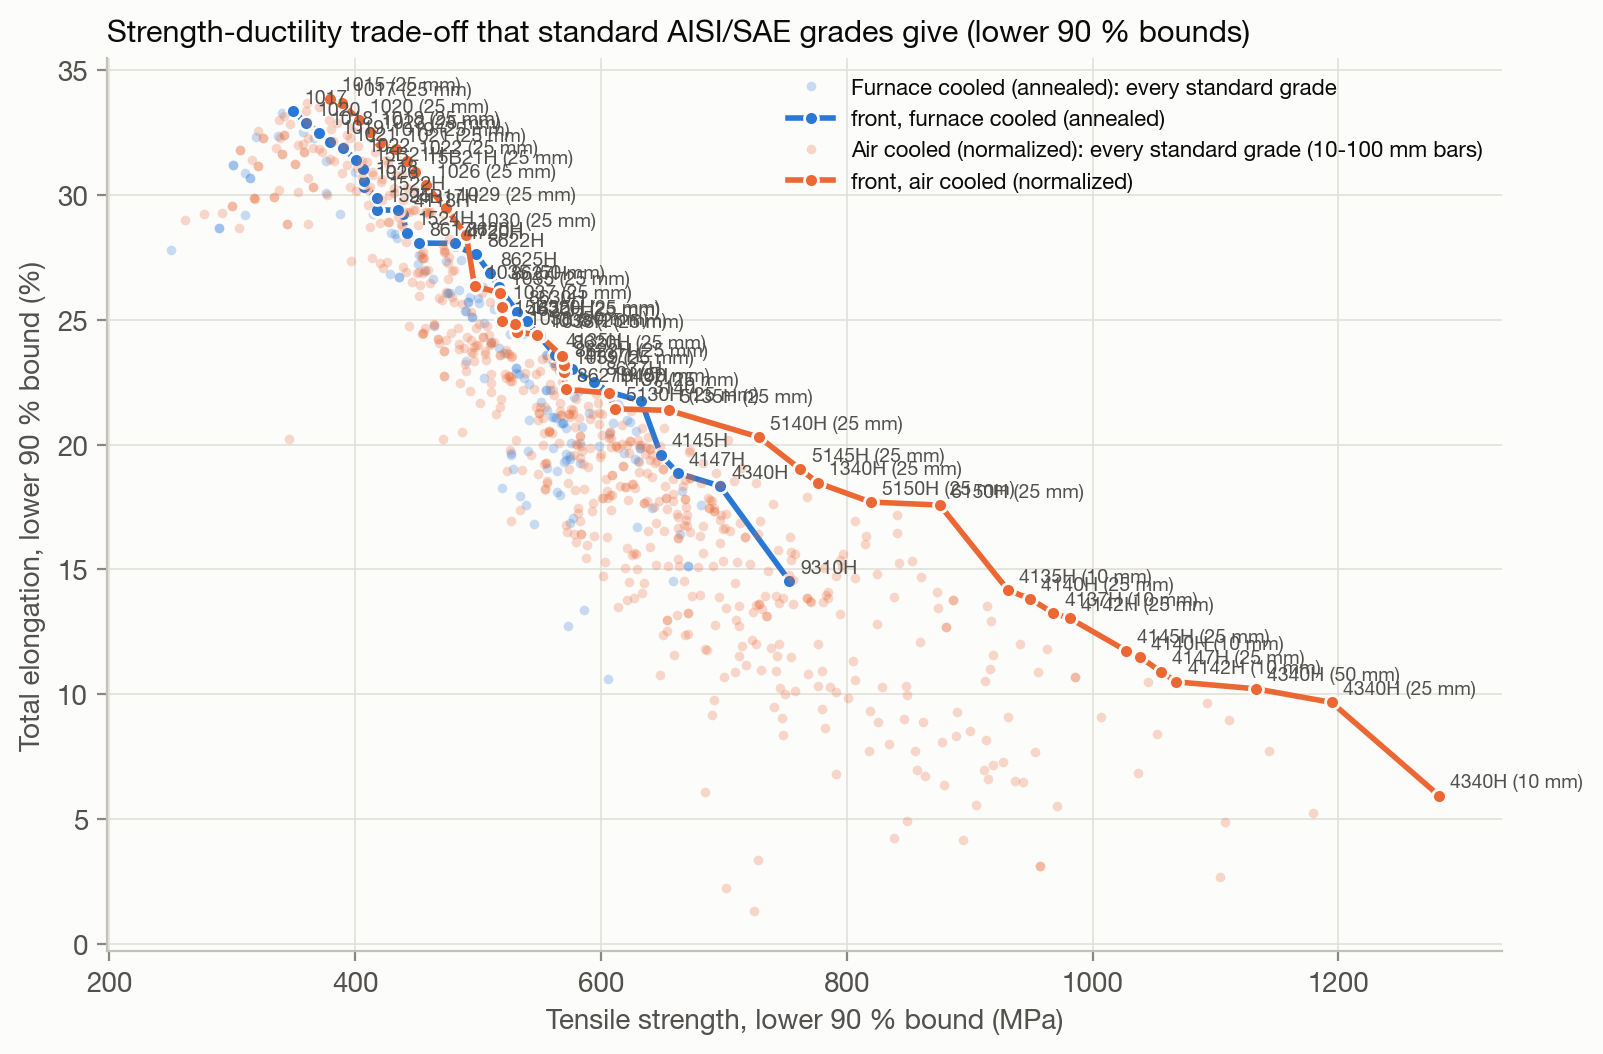

In [3]:
fig("fig22_grade_front_fc_vs_ac", 800)

In [4]:
al = pd.read_csv(R / "s07_active_learning.csv")
al.groupby(["n_grades", "strategy"]).RMSE.mean().unstack().round(1)

strategy,random,uncertainty
n_grades,,
8,111,111
9,121,104
10,114,111
11,102,87.2
12,101,84.2
13,94.8,79.6
14,95.6,77
15,91.7,72.9
16,94.4,72.2


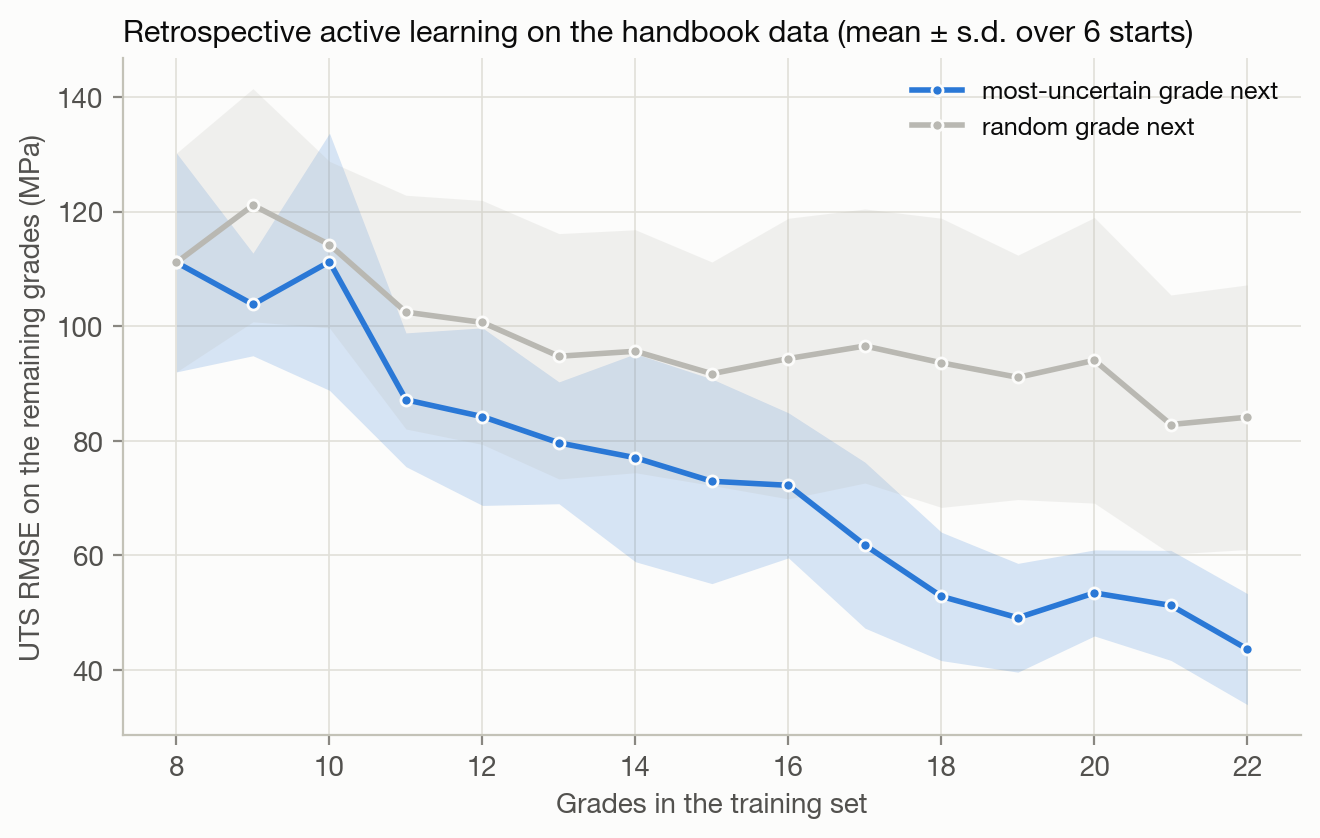

In [5]:
fig("fig23_active_learning", 750)

In [6]:
pd.read_csv(R / "s07_few_shot.csv").groupby(["target", "k_added"])[["RMSE", "bias"]].mean().round(1)

RMSE  bias
target  k_added            
UTS_MPa 0        58.8 -48.5
        5        35.9   -13
        10       29.4  -4.8
        20       25.8    -5
        40       24.5  -3.3
YS_MPa  0        81.8 -60.1
        5        56.1 -24.9
        10       48.3   -16
        20       40.2  -8.1
        40       37.1  -4.8

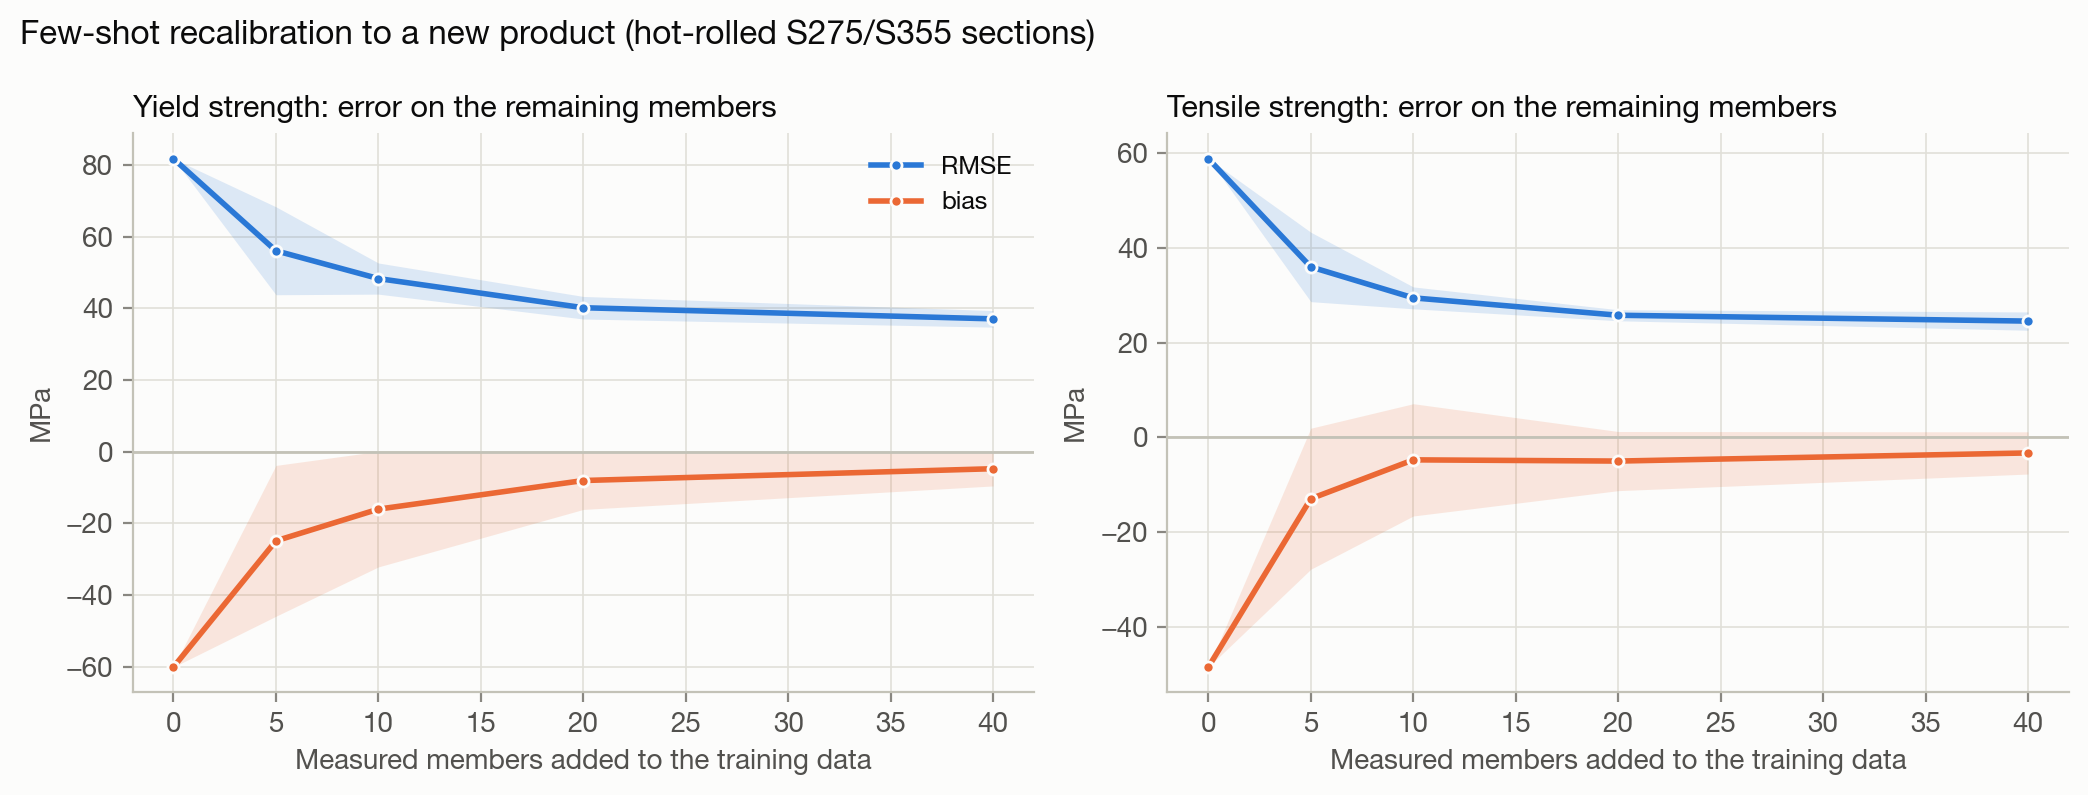

In [7]:
fig("fig24_few_shot_recalibration", 900)

## Pre-registered laboratory plan
Predictions are fixed *before* the experiments, so the lab results are a genuine test. Steels commonly
stocked in Indian laboratories are listed with their AISI equivalents, ranked by expected information
(width of the prediction intervals).

In [8]:
pd.read_csv(R / "s07_lab_plan_preregistered.csv")

,steel,option,austenitise_C,ferrite_frac,pearlite_frac,bainite_frac,martensite_frac,pearlite_spacing_nm,YS_MPa_pred,YS_MPa_90PI,UTS_MPa_pred,UTS_MPa_90PI,El_pct_pred,El_pct_90PI,HB_pred,HB_90PI,uniform_El_est_pct,uniform_El_90PI,in_domain,microstructure_in_data,relative_uncertainty,priority_rank
0,EN24 (~AISI 4340),"air cool, 10 mm bar",870,0,0,0.65,0.33,NaN,909,"[578, 1240]",1.52e+03,"[1282, 1753]",11,"[6, 16]",410,"[326, 495]",5.6,"[3, 10]",True,True,0.594,1
1,EN42 (~AISI 1080),"air cool, 10 mm bar",870,0,1,0,0,148,557,"[407, 707]",1.05e+03,"[912, 1179]",11.1,"[7, 15]",300,"[252, 347]",5.6,"[3, 9]",True,True,0.463,2
2,EN353-type (~AISI 8620),"air cool, 10 mm bar",918,0.42,0.16,0.42,0,129,403,"[288, 518]",666,"[549, 783]",24.2,"[19, 30]",191,"[153, 230]",12.3,"[8, 18]",True,True,0.442,3
3,EN18 (~AISI 5140),"air cool, 10 mm bar",889,0.26,0.38,0.36,0,131,492,"[373, 612]",815,"[713, 918]",21.5,"[17, 26]",226,"[188, 265]",10.9,"[7, 15]",True,True,0.377,4
4,EN3B (~AISI 1018),"air cool, 10 mm bar",931,0.78,0.22,0,0,261,350,"[251, 449]",464,"[414, 515]",35.1,"[31, 39]",138,"[104, 171]",17.8,"[13, 23]",True,True,0.376,5
5,EN9 (~AISI 1055),"air cool, 10 mm bar",870,0.26,0.74,0,0,196,467,"[355, 579]",800,"[709, 890]",18.3,"[14, 22]",233,"[196, 271]",9.3,"[6, 13]",True,True,0.361,6
6,EN8 (~AISI 1045),"air cool, 10 mm bar",879,0.38,0.62,0,0,198,433,"[330, 535]",707,"[625, 788]",22.2,"[18, 26]",214,"[178, 249]",11.3,"[8, 15]",True,True,0.346,7
7,EN19 (~AISI 4140),"air cool, 10 mm bar",887,0.01,0.01,0.99,0,NaN,698,"[558, 838]",1.14e+03,"[1039, 1249]",15.5,"[11, 20]",325,"[285, 366]",7.9,"[5, 12]",True,True,0.339,8
8,EN18 (~AISI 5140),furnace cool (~18 K/h),829,0.4,0.6,0,0,460,333,"[281, 386]",583,"[537, 630]",27.8,"[24, 31]",172,"[152, 192]",14.1,"[10, 18]",True,True,0.238,9
9,EN42 (~AISI 1080),furnace cool (~18 K/h),783,0,0.99,0,0,512,381,"[335, 427]",626,"[575, 677]",23.1,"[20, 27]",180,"[159, 202]",11.7,"[8, 16]",True,True,0.238,10
